# Phase 3: Python Visualisations
Run `01_clean_data.ipynb` first. This notebook reads `outputs/cleaned_train.csv`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

train = pd.read_csv("outputs/cleaned_train.csv", parse_dates=["Date of Onset/Emergence", "Reporting Date"])
measles = train[train["Disease/Condition"] == "Measles"].copy()
measles.shape

(3295, 66)

## 1. Epidemic curve (Epicurve)
* x-axis: **epi week of rash onset** (week starting Monday)
* bars **stacked** by final classification
* bars **touch each other** (no gaps), because time is continuous

In [2]:
# keep the outbreak period: almost all cases were reported between January and April 2026.
# A few onset dates are typos far outside that period (e.g. 2006, 2027), so we leave them out of the chart.
in_window = measles["Date of Onset/Emergence"].between("2025-11-15", "2026-04-30")
print("Cases outside the outbreak window (not plotted):", (~in_window & measles["Date of Onset/Emergence"].notna()).sum())

epi = measles[in_window].copy()

# Monday of the onset week:  date - day of week  (Monday = 0)
epi["Week start"] = epi["Date of Onset/Emergence"] - pd.to_timedelta(epi["Date of Onset/Emergence"].dt.dayofweek, unit="D")
epi["Week start"].head()

Cases outside the outbreak window (not plotted): 35


0   2026-03-09
1   2026-03-23
2   2026-04-06
3   2026-02-16
4   2026-04-06
Name: Week start, dtype: datetime64[us]

In [3]:
# cases per week and classification (group by + unstack, as in class)
weekly = epi.groupby(["Week start", "Final Epi-classification (std)"]).size().unstack(fill_value=0)

# add weeks with zero cases so the time axis has no holes
all_weeks = pd.date_range(weekly.index.min(), weekly.index.max(), freq="7D")
weekly = weekly.reindex(all_weeks, fill_value=0)
weekly.head()

Final Epi-classification (std),Clinically Compatible,Discarded,Epidemiologically Linked,Laboratory-Confirmed,Missing,Suspected/Pending/Other
2025-12-08,1,0,0,0,0,0
2025-12-15,6,0,0,0,0,0
2025-12-22,13,0,0,0,0,8
2025-12-29,52,0,0,0,1,13
2026-01-05,51,0,3,0,1,17


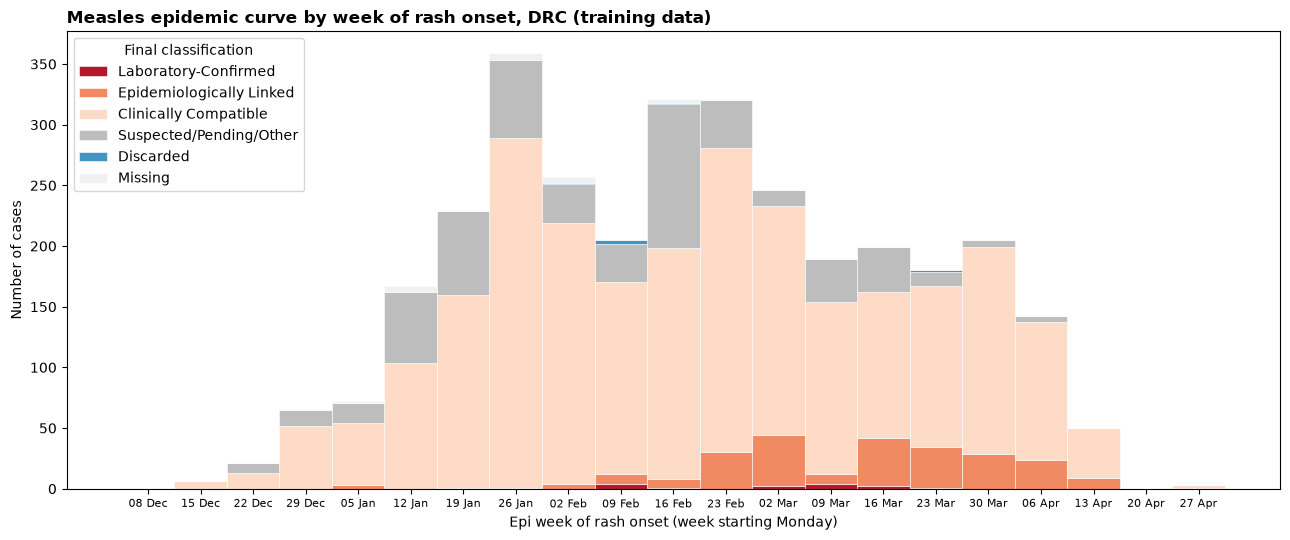

In [4]:
order = ["Laboratory-Confirmed", "Epidemiologically Linked", "Clinically Compatible",
         "Suspected/Pending/Other", "Discarded", "Missing"]
colors = ["#b2182b", "#ef8a62", "#fddbc7", "#bdbdbd", "#4393c3", "#f0f0f0"]

plt.figure(figsize=(13, 5.5))
bottom = np.zeros(len(weekly))
for category, color in zip(order, colors):
    if category in weekly.columns:
        plt.bar(weekly.index, weekly[category], bottom=bottom,
                width=7,          # one bar = 7 days -> bars touch
                align="edge",     # bar starts on the Monday
                color=color, edgecolor="white", linewidth=0.4, label=category)
        bottom = bottom + weekly[category].values

week_labels = weekly.index.strftime("%d %b")    # e.g. "26 Jan" = the Monday of that week
plt.xticks(weekly.index + pd.Timedelta(days=3.5), week_labels, fontsize=8)
plt.title("Measles epidemic curve by week of rash onset, DRC (training data)", loc="left", fontweight="bold")
plt.xlabel("Epi week of rash onset (week starting Monday)")
plt.ylabel("Number of cases")
plt.legend(title="Final classification", loc="upper left")
plt.tight_layout()
plt.savefig("outputs/epicurve.png", dpi=200)
plt.show()

**Formatting choices (Q3.1):** `width=7` (one bar = one full week) and `align="edge"` (bar starts on the Monday) make the bars touch, so the curve reads as continuous time;
empty weeks are added with zero cases instead of being skipped; the y-axis starts at zero; the stacking shows how much of each week is lab-confirmed vs only clinically compatible.

## 2. Vaccination doses by age cohort

In [5]:
age_order = ["<1 year", "1-4 years", "5-9 years", "10-14 years", "15+ years"]
dose_order = ["Zero-Dose", "1 Dose", "2+ Doses", "Unknown"]

doses_by_age = (measles.groupby("Age Group")["Dose Group"].value_counts(normalize=True) * 100).unstack()
doses_by_age = doses_by_age.reindex(index=age_order, columns=dose_order).round(1)
doses_by_age

Dose Group,Zero-Dose,1 Dose,2+ Doses,Unknown
Age Group,,,,
<1 year,58.3,19.1,2.3,20.2
1-4 years,28.5,44.7,8.9,18.0
5-9 years,29.0,38.5,10.8,21.7
10-14 years,39.2,31.4,7.4,22.0
15+ years,42.3,25.4,3.2,29.1


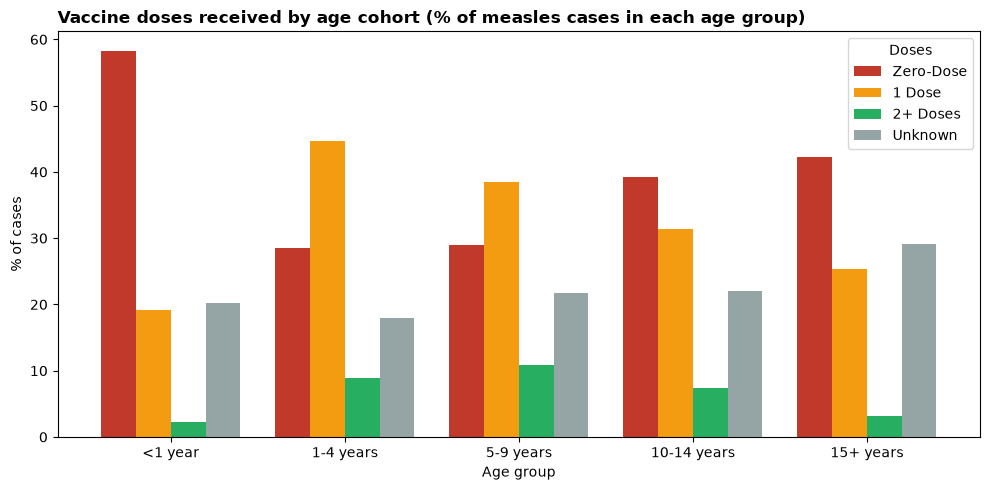

In [6]:
doses_by_age.plot(kind="bar", figsize=(10, 5), color=["#c0392b", "#f39c12", "#27ae60", "#95a5a6"], width=0.8)
plt.title("Vaccine doses received by age cohort (% of measles cases in each age group)", loc="left", fontweight="bold")
plt.xlabel("Age group")
plt.ylabel("% of cases")
plt.xticks(rotation=0)
plt.legend(title="Doses")
plt.tight_layout()
plt.savefig("outputs/vaccination_by_age.png", dpi=200)
plt.show()

## 3. Zero-dose hot spots (to compare with the Power BI map, Q3.2)

In [7]:
measles["Zero dose"] = measles["Dose Group"] == "Zero-Dose"

hotspots = measles.groupby(["Reporting County", "Reporting District"]).agg(
    cases=("Zero dose", "count"),
    zero_dose_cases=("Zero dose", "sum"),
)
hotspots["% zero dose"] = (hotspots["zero_dose_cases"] / hotspots["cases"] * 100).round(1)
hotspots = hotspots.sort_values("zero_dose_cases", ascending=False)
hotspots.to_csv("outputs/zero_dose_hotspots.csv")
hotspots.head(10)

,,cases,zero_dose_cases,% zero dose
Reporting County,Reporting District,,,
Kongo Central,Lubero,417,213,51.1
Kinshasa,Ngiri-Ngiri,384,198,51.6
Kongo Central,Mwenga,86,82,95.3
Kinshasa,Lubumbashi,389,71,18.3
Sud-Kivu,Kintambo,79,64,81.0
Kinshasa,Boma,134,63,47.0
Nord-Kivu,Lemba,81,45,55.6
Sud-Kivu,Kenge,52,40,76.9
Kwango,Masisi,64,39,60.9


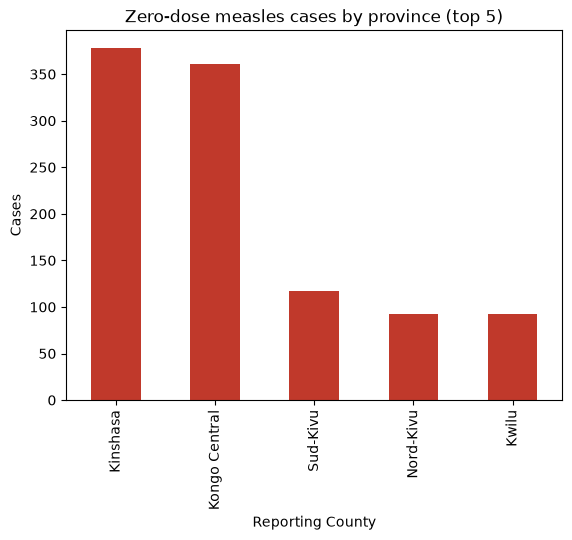

In [8]:
measles.groupby("Reporting County")["Zero dose"].sum().sort_values(ascending=False).head(5).plot(kind="bar", color="#c0392b")
plt.title("Zero-dose measles cases by province (top 5)")
plt.ylabel("Cases")
plt.show()